In [3]:
import numpy as np
from pathlib import Path
import timeit
import pandas as pd
import sys
sys.path.insert(1, '../')
import util
from util.dynamics import temp_response, environmental_update
from util.plot import lighten_color

import scipy as sp
import matplotlib.pyplot as plt
# import tqdm
from matplotlib.lines import Line2D

import tqdm
import seaborn as sns
from scipy.optimize import fsolve
import os

In [28]:
def OS_model(t, T_0,T_peak,T_os,t_up,t_down):
    if t <= t_up:
        return T_0 + t*(T_peak-T_0)/t_up
    elif t <= t_up+t_down:
        return T_peak - (t-t_up)*(T_peak-T_os)/(t_down)
    else:
        return T_os

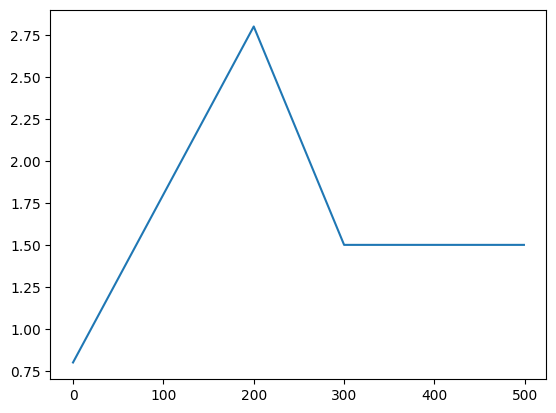

In [10]:
years = np.arange(500)
temp = np.array([OS_model(y,0.8,2.8,1.5,200,100) for y in years])
plt.plot(years,temp)

# Using PROVIDE Project scenarios
Robin Lamboll, Joeri Rogelj, & Carl-Friedrich Schleussner. (2025). Scenario emissions and temperature data for PROVIDE project (v1.3.0) [Data set]. Zenodo. https://doi.org/10.5281/zenodo.11108741

https://pure.iiasa.ac.at/id/eprint/18130/1/essoar.10511875.2.pdf for description

In [12]:
folder = '../../Data/PROVIDE 2025/'
cols = list(pd.read_csv(folder+'post-2100_inc_redundanttier1_temperature_summary.csv',nrows=1))
df = pd.read_csv(folder+'post-2100_inc_redundanttier1_temperature_summary.csv',
                 usecols = [c for c in cols if (c != 'quantile') and (c!= 'atomic_scen')]).set_index('scenario').T
df.index.names=['year']
# df=df.rename(columns={'scenario':''})
scenarios = df.columns.values

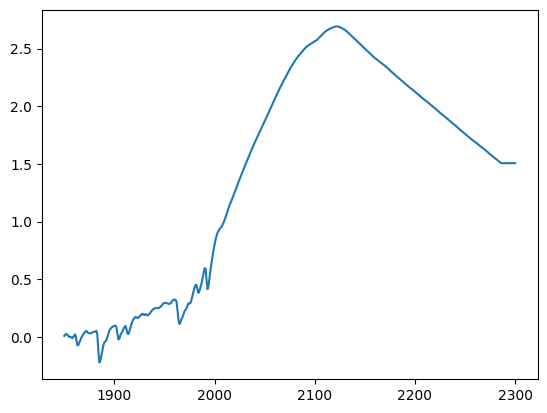

In [16]:
temp = df['ModAct_OS_1.5C'].to_numpy()
years= np.arange(1850,2301)
plt.plot(years,temp)

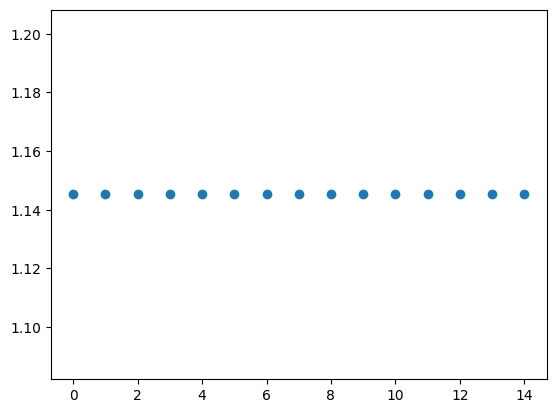

In [26]:
plt.scatter(range(len(scenarios)),[df[s].to_numpy()[2015-1850] for s in scenarios])

In [18]:
from scipy.optimize import curve_fit

In [33]:
t_ref=2015
T_ref=temp[t_ref-1850]
T_max=temp.max()
xdata = np.arange(t_ref,2301)-t_ref
ydata=temp[t_ref-1850:]
popt, pcov = curve_fit(OS_model, xdata, ydata,
                       p0=[T_ref, T_max, T_ref, (T_max-T_ref)/0.01, (temp.max()-T_ref)/0.01],
                       bounds = ([T_ref-0.5, T_max-0.5, T_ref-0.5, 10, 10],
                                 [T_ref+0.5, T_max+0.5, T_max+0.5, len(ydata), len(ydata)]) )
                       # bounds=[(T_ref-0.5,T_ref+0.5), 
                       #         (T_max-0.5,T_max+0.5),
                       #         (T_ref-0.5,T_max+0.5), 
                       #         (10,500), 
                       #         (10,500)])

ValueError: The truth value of an array with more than one element is ambiguous. Use a.any() or a.all()

In [22]:
len(temp[2015-1850:])

286